<p style="background-color:firebrick;font-family:newtimeroman;font-size:200%;color:white;text-align:center;border-radius:20px 20px;"><b>EDA Project</b></p>

<b>Contains:</b>
<ul>
<li><a href="#import-library">Importing Libraries</a></li>
<li><a href="#loading-dataset">Loading The Dataset</a></li>
<li><a href="#understanding-dataset">Understanding The Dataset</a></li>
<li><a href="#organizing-columns">Organizing Columns</a></li>
<li><a href="#nan-values">NaN Values</a></li>
<li><a href="#data-visualization">Data Visualization</a></li>
<li><a href="#save-data">Save  to Dataset</a></li>
</ul>

<a id='import-library'></a>
## <font color='firebrick'> <b>Importing Libraries</b><font color='black'>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import missingno as msno
import plotly.express as px

from skimpy import skim

import warnings
warnings.filterwarnings("ignore")

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [2]:
!pip install skimpy missingno

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 84.3 MB/s  0:00:00
  Attempting uninstall: jupyter-client
    Found existing installation: jupyter_client 7.4.9
    Uninstalling jupyter_client-7.4.9:
      Successfully uninstalled jupyter_client-7.4.9
  Attempting uninstall: ipykernel
    Found existing installation: ipykernel 6.17.1
    Uninstalling ipykernel-6.17.1:
      Successfully uninstalled ipykernel-6.17.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [skimpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires ipykernel==6.17.1, but you have ipykernel 7.4.0 which is incompatible.
notebook 6.5.7 requires jupyter-client<8,>=5.3.4, but you have jupyter-client 8.10.0 which is incompatible.
jupyter-kernel-gateway 2.5.2 requires jupyter_client<8.0,>=5.2.0, but you have jupyter-client 8.10.0 which is incompatible.


<a id='loading-dataset'></a>
## <font color='firebrick'> <b>Loading The Dataset</b><font color='black'>

In [3]:
df0 = pd.read_csv("realistic_e_commerce_sales_data.csv")
df = df0.copy()

In [4]:
import os
print(os.listdir('/content'))

['.config', 'realistic_e_commerce_sales_data.csv', 'sample_data']


In [5]:
import pandas as pd
import os

files = [f for f in os.listdir('/content') if f.lower().endswith('.csv')]
print(files)

['realistic_e_commerce_sales_data.csv']


In [6]:
import pandas as pd

df0 = pd.read_csv('/content/realistic_e_commerce_sales_data.csv')
df = df0.copy()

df.head()

,Customer ID,Gender,Region,Age,Product Name,Category,Unit Price,Quantity,Total Price,Shipping Fee,Shipping Status,Order Date
0,CUST0268,Male,North,NaN,Monitor,Electronics,300.0,5,1500,13.31,Returned,2023-12-08
1,CUST0046,Male,West,22.0,Headphones,Accessories,100.0,2,200,6.93,In Transit,2023-04-09
2,CUST0169,Female,South,54.0,Monitor,Electronics,300.0,1,300,11.31,Returned,2023-08-28
3,CUST0002,Male,North,23.0,Headphones,Accessories,100.0,5,500,12.22,Delivered,2023-01-18
4,CUST0173,Female,South,NaN,Laptop,Electronics,1500.0,3,4500,5.40,Delivered,2023-01-19


In [7]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.info()

Dataset shape: (1000, 12)

Column names:
['Customer ID', 'Gender', 'Region', 'Age', 'Product Name', 'Category', 'Unit Price', 'Quantity', 'Total Price', 'Shipping Fee', 'Shipping Status', 'Order Date']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer ID      1000 non-null   object 
 1   Gender           1000 non-null   object 
 2   Region           950 non-null    object 
 3   Age              900 non-null    float64
 4   Product Name     1000 non-null   object 
 5   Category         1000 non-null   object 
 6   Unit Price       1000 non-null   float64
 7   Quantity         1000 non-null   int64  
 8   Total Price      1000 non-null   int64  
 9   Shipping Fee     1000 non-null   float64
 10  Shipping Status  950 non-null    object 
 11  Order Date       1000 non-null   object 
dtypes: float64(3), int64(2), object(7)
memory u

In [8]:
df.sample(5)

,Customer ID,Gender,Region,Age,Product Name,Category,Unit Price,Quantity,Total Price,Shipping Fee,Shipping Status,Order Date
760,CUST0191,Female,NaN,41.0,Laptop,Electronics,1500.0,4,6000,6.76,NaN,2023-08-01
340,CUST0053,Male,NaN,25.0,Keyboard,Accessories,50.0,3,150,11.95,Returned,2023-10-18
669,CUST0177,Female,East,29.0,Smartwatch,Wearables,200.0,4,800,17.93,Delivered,2023-02-25
482,CUST0243,Female,West,58.0,Headphones,Accessories,100.0,5,500,19.98,Returned,2023-08-13
143,CUST0281,Male,West,44.0,Keyboard,Accessories,50.0,4,200,19.81,In Transit,2023-08-27


<a id='understanding-dataset'></a>
##  <font color='firebrick'> <b>Understanding The Dataset</b><font color='black'>

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer ID      1000 non-null   object 
 1   Gender           1000 non-null   object 
 2   Region           950 non-null    object 
 3   Age              900 non-null    float64
 4   Product Name     1000 non-null   object 
 5   Category         1000 non-null   object 
 6   Unit Price       1000 non-null   float64
 7   Quantity         1000 non-null   int64  
 8   Total Price      1000 non-null   int64  
 9   Shipping Fee     1000 non-null   float64
 10  Shipping Status  950 non-null    object 
 11  Order Date       1000 non-null   object 
dtypes: float64(3), int64(2), object(7)
memory usage: 93.9+ KB


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,900.0,46.695556,15.011400,18.0,35.00,49.000,59.000,69.000000
Unit Price,1000.0,457.703777,537.231434,30.0,50.00,200.000,800.000,3109.560612
Quantity,1000.0,3.008000,1.404246,1.0,2.00,3.000,4.000,5.000000
Total Price,1000.0,1346.600000,1834.037877,30.0,200.00,600.000,1500.000,7500.000000
Shipping Fee,1000.0,12.416390,4.412185,5.0,8.56,12.315,16.075,19.980000


In [10]:
df.describe(include = 'object').T

,count,unique,top,freq
Customer ID,1000,292,CUST0052,9
Gender,1000,2,Male,524
Region,950,4,West,246
Product Name,1000,7,Monitor,181
Category,1000,3,Electronics,477
Shipping Status,950,3,In Transit,329
Order Date,1000,340,2024-01-03,20


In [11]:
df.isnull().sum()

,0
Customer ID,0
Gender,0
Region,50
Age,100
Product Name,0
Category,0
Unit Price,0
Quantity,0
Total Price,0
Shipping Fee,0


In [12]:
skim(df)

╭──────────────────────────────────────────────── skimpy summary ─────────────────────────────────────────────────╮
│          Data Summary                Data Types                                                                 │
│ ┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓ ┏━━━━━━━━━━━━━┳━━━━━━━┓                                                          │
│ ┃ Dataframe         ┃ Values ┃ ┃ Column Type ┃ Count ┃                                                          │
│ ┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩ ┡━━━━━━━━━━━━━╇━━━━━━━┩                                                          │
│ │ Number of rows    │ 1000   │ │ string      │ 7     │                                                          │
│ │ Number of columns │ 12     │ │ float64     │ 3     │                                                          │
│ └───────────────────┴────────┘ │ int64       │ 2     │                                                          │
│                                └─────────────┴───────┘                                                          │
│                                                     number                                                      │
│ ┏━━━━━━━━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┓  │
│ ┃ column           ┃ NA    ┃ NA %   ┃ mean    ┃ sd      ┃ p0  ┃ p25    ┃ p50     ┃ p75    ┃ p100   ┃ hist    ┃  │
│ ┡━━━━━━━━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━┩  │
│ │ Age              │   100 │     10 │    46.7 │   15.01 │  18 │     35 │      49 │     59 │     69 │ ▄▄▆▅▇█  │  │
│ │ Unit Price       │     0 │      0 │   457.7 │   537.2 │  30 │     50 │     200 │    800 │   3110 │   █▂▂   │  │
│ │ Quantity         │     0 │      0 │   3.008 │   1.404 │   1 │      2 │       3 │      4 │      5 │ ▇▇ ██▇  │  │
│ │ Total Price      │     0 │      0 │    1347 │    1834 │  30 │    200 │     600 │   1500 │   7500 │  █▁▁▁   │  │
│ │ Shipping Fee     │     0 │      0 │   12.42 │   4.412 │   5 │   8.56 │   12.32 │  16.07 │  19.98 │ █▇▇▇▆█  │  │
│ └──────────────────┴───────┴────────┴─────────┴─────────┴─────┴────────┴─────────┴────────┴────────┴─────────┘  │
│                                                     string                                                      │
│ ┏━━━━━━━━━━━┳━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┓  │
│ ┃           ┃    ┃      ┃           ┃           ┃           ┃           ┃ chars per ┃ words per  ┃ total     ┃  │
│ ┃ column    ┃ NA ┃ NA % ┃ shortest  ┃ longest   ┃ min       ┃ max       ┃ row       ┃ row        ┃ words     ┃  │
│ ┡━━━━━━━━━━━╇━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━┩  │
│ │ Customer  │  0 │    0 │ CUST0268  │ CUST0268  │ CUST0001  │ CUST0300  │         8 │          1 │      1000 │  │
│ │ ID        │    │      │           │           │           │           │           │            │           │  │
│ │ Gender    │  0 │    0 │ Male      │ Female    │ Female    │ Male      │      4.95 │          1 │      1000 │  │
│ │ Region    │ 50 │    5 │ West      │ North     │ East      │ West      │       4.5 │       0.95 │       950 │  │
│ │ Product   │  0 │    0 │ Mouse     │ Headphone │ Headphone │ Smartwatc │      7.87 │          1 │      1000 │  │
│ │ Name      │    │      │           │ s         │ s         │ h         │           │            │           │  │
│ │ Category  │  0 │    0 │ Wearables │ Electroni │ Accessori │ Wearables │      10.8 │          1 │      1000 │  │
│ │           │    │      │           │ cs        │ es        │           │           │            │           │  │
│ │ Shipping  │ 50 │    5 │ Returned  │ In        │ Delivered │ Returned  │      9.02 │        1.3 │      1279 │  │
│ │ Status    │    │      │           │ Transit   │           │           │           │            │           │  │
│ │ Order     │  0 │    0 │ 2023-12-0 │ 2023-12-0 │ 2023

<Axes: >

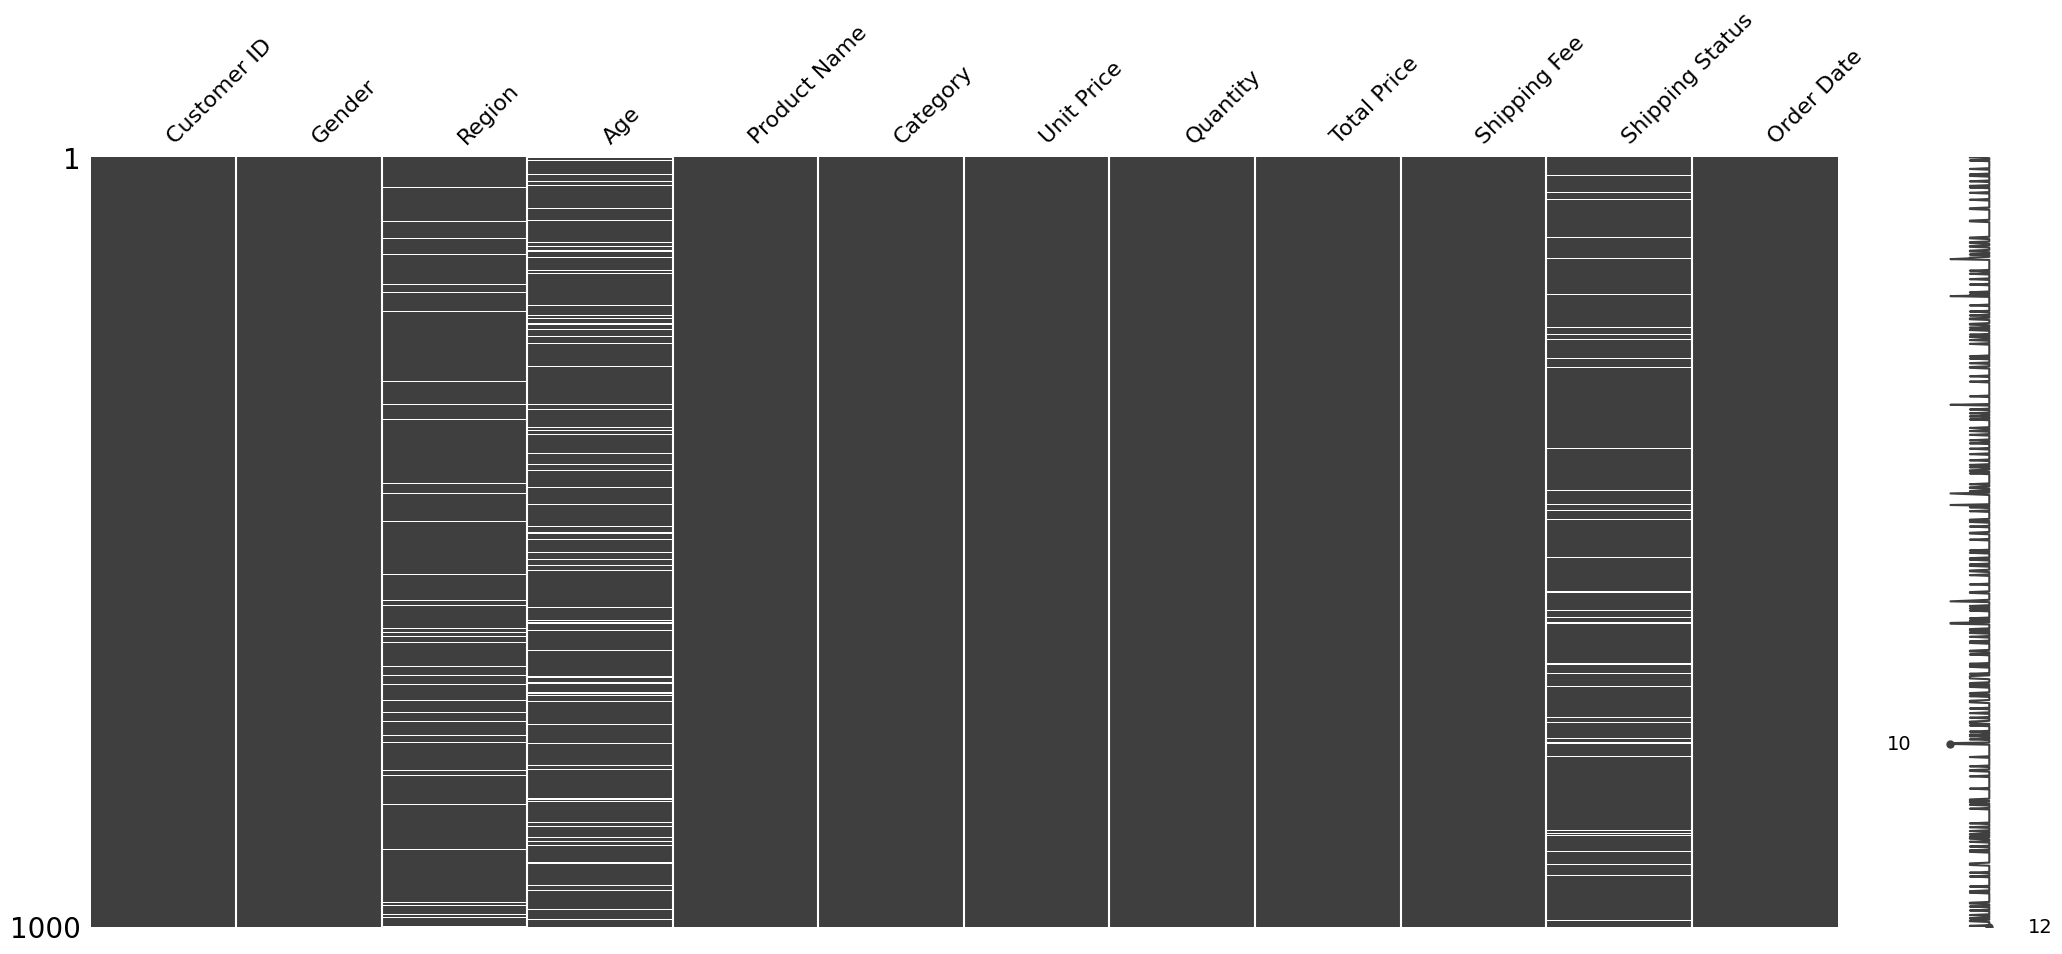

In [13]:
msno.matrix(df)

<a id='organizing-columns'></a>
##  <font color='firebrick'> <b>Organizing Columns</b><font color='black'>

In [18]:
df.columns

Index(['customer_id', 'gender', 'region', 'age', 'product_name', 'category',
       'unit_price', 'quantity', 'total_price', 'shipping_fee',
       'shipping_status', 'order_date'],
      dtype='object')

In [15]:
df.columns=df.columns.str.replace(" ","_").str.lower()
df.columns

Index(['customer_id', 'gender', 'region', 'age', 'product_name', 'category',
       'unit_price', 'quantity', 'total_price', 'shipping_fee',
       'shipping_status', 'order_date'],
      dtype='object')

In [16]:
df.shape

(1000, 12)

In [17]:
df.duplicated().sum()

np.int64(0)

## <font color='orange'> <b> Customer ID </b><font color='black'>

In [19]:
df.customer_id.nunique()

292

## <font color='orange'> <b> Gender </b><font color='black'>

In [20]:
df.gender.nunique()

2

## <font color='orange'> <b> Shipping Status </b><font color='black'>

In [21]:
df.shipping_status.nunique()

3

## <font color='orange'> <b> Age </b><font color='black'>

In [22]:
df.age.nunique()

52

In [23]:
df.age.unique()

array([nan, 22., 54., 23., 64., 27., 18., 29., 49., 67., 41., 60., 66.,
       36., 57., 30., 32., 59., 37., 52., 58., 25., 31., 28., 53., 35.,
       43., 61., 19., 38., 44., 68., 42., 51., 46., 62., 33., 24., 21.,
       50., 48., 63., 47., 45., 40., 55., 69., 26., 20., 65., 39., 56.,
       34.])

## <font color='orange'> <b> Category </b><font color='black'>

In [24]:
df.category.unique()

array(['Electronics', 'Accessories', 'Wearables'], dtype=object)

## <font color='orange'> <b> Unit Price </b><font color='black'>

In [25]:
df.unit_price.nunique()

13

In [26]:
df.unit_price.unique()

array([ 300.        ,  100.        , 1500.        ,  200.        ,
         50.        ,   30.        ,  800.        , 1658.43232666,
         62.19121225,  103.65202042,  621.9121225 ,  207.30404083,
       3109.56061249])

In [27]:
df.unit_price = round(df.unit_price,2)

In [28]:
df.unit_price.nunique()

13

## <font color='orange'> <b> Quantity </b><font color='black'>

In [29]:
df.quantity.nunique()

5

In [30]:
df.quantity.unique()

array([5, 2, 1, 3, 4])

## <font color='orange'> <b> Shipping Fee </b><font color='black'>

In [ ]:
df.shipping_fee.nunique()

## <font color='orange'> <b> Shipping Status </b><font color='black'>

In [31]:
df.shipping_status.nunique()

3

In [32]:
df.shipping_status.unique()

array(['Returned', 'In Transit', 'Delivered', nan], dtype=object)

## <font color='orange'> <b> Order Date </b><font color='black'>

In [33]:
df.order_date.nunique()

340

In [34]:
df.order_date.dtype

dtype('O')

In [35]:
df['order_date'] = pd.to_datetime(df['order_date'])

<a id='nan-values'></a>
## <font color='firebrick'> <b>NaN Values</b><font color='black'>

In [36]:
df.isnull().sum()

,0
customer_id,0
gender,0
region,50
age,100
product_name,0
category,0
unit_price,0
quantity,0
total_price,0
shipping_fee,0


In [37]:
df.groupby(["product_name","region"])[["category"]].count()

category
product_name region          
Headphones   East          35
             North         26
             South         25
             West          28
Keyboard     East          25
             North         33
             South         38
             West          42
Laptop       East          35
             North         39
             South         32
             West          41
Monitor      East          40
             North         43
             South         52
             West          42
Mouse        East          29
             North         30
             South         33
             West          35
Smartphone   East          33
             North         31
             South         35
             West          33
Smartwatch   East          34
             North         27
             South         29
             West          25

In [38]:
df.groupby('product_name')['region'].apply(lambda x: x.mode()[0])

,region
product_name,
Headphones,East
Keyboard,West
Laptop,West
Monitor,South
Mouse,West
Smartphone,South
Smartwatch,East


In [39]:
df['region'] = df['region'].fillna(df['product_name'].map( df.groupby('product_name')['region'].apply(lambda x: x.mode()[0])))

In [40]:
df.isnull().sum()

,0
customer_id,0
gender,0
region,0
age,100
product_name,0
category,0
unit_price,0
quantity,0
total_price,0
shipping_fee,0


In [ ]:
df.region.describe()

In [ ]:
df.sample(5)

In [ ]:
df.groupby(["customer_id","shipping_status"])[["customer_id"]].count()

In [41]:
df['shipping_status'] = df['shipping_status'].fillna(df['customer_id'].map(df.groupby('customer_id')['shipping_status'].apply(lambda x: x.mode()[0] if not x.mode().empty else None)))

In [42]:
df.isnull().sum()

,0
customer_id,0
gender,0
region,0
age,100
product_name,0
category,0
unit_price,0
quantity,0
total_price,0
shipping_fee,0


In [43]:
df['shipping_status'] = df['shipping_status'].fillna(df['shipping_status'].mode()[0])

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   customer_id      1000 non-null   object        
 1   gender           1000 non-null   object        
 2   region           1000 non-null   object        
 3   age              900 non-null    float64       
 4   product_name     1000 non-null   object        
 5   category         1000 non-null   object        
 6   unit_price       1000 non-null   float64       
 7   quantity         1000 non-null   int64         
 8   total_price      1000 non-null   int64         
 9   shipping_fee     1000 non-null   float64       
 10  shipping_status  1000 non-null   object        
 11  order_date       1000 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), int64(2), object(6)
memory usage: 93.9+ KB


In [45]:
df['shipping_status'].fillna(df['customer_id'].map(df.groupby('customer_id')['shipping_status'].apply(lambda x: x.mode()[0] if not x.mode().empty else None)))

,shipping_status
0,Returned
1,In Transit
2,Returned
3,Delivered
4,Delivered
5,In Transit
6,In Transit
7,Returned
8,Returned
9,Delivered


In [46]:
df['age'] = df['age'].fillna(df['customer_id'].map(df.groupby('customer_id')['age'].apply(lambda x: x.mode()[0] if not x.mode().empty else None)))

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   customer_id      1000 non-null   object        
 1   gender           1000 non-null   object        
 2   region           1000 non-null   object        
 3   age              993 non-null    float64       
 4   product_name     1000 non-null   object        
 5   category         1000 non-null   object        
 6   unit_price       1000 non-null   float64       
 7   quantity         1000 non-null   int64         
 8   total_price      1000 non-null   int64         
 9   shipping_fee     1000 non-null   float64       
 10  shipping_status  1000 non-null   object        
 11  order_date       1000 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), int64(2), object(6)
memory usage: 93.9+ KB


In [48]:
df.age = df.age.fillna(df.age.median())
df2 = df

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   customer_id      1000 non-null   object        
 1   gender           1000 non-null   object        
 2   region           1000 non-null   object        
 3   age              1000 non-null   float64       
 4   product_name     1000 non-null   object        
 5   category         1000 non-null   object        
 6   unit_price       1000 non-null   float64       
 7   quantity         1000 non-null   int64         
 8   total_price      1000 non-null   int64         
 9   shipping_fee     1000 non-null   float64       
 10  shipping_status  1000 non-null   object        
 11  order_date       1000 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), int64(2), object(6)
memory usage: 93.9+ KB


<a id='data-visualization'></a>
## <font color='firebrick'> <b>Data Visualization</b><font color='black'>

In [50]:
type_counts = df['gender'].value_counts()
type_counts

,count
gender,
Male,524
Female,476


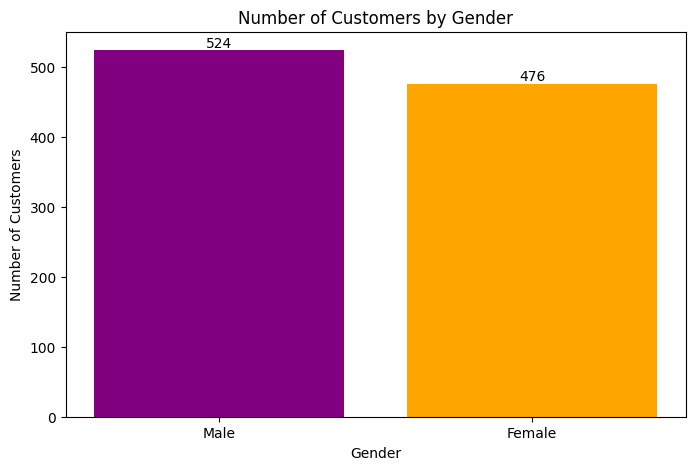

In [51]:
plt.figure(figsize=(8, 5))  # Graph's size
bars = plt.bar(type_counts.index, type_counts.values, color=['purple', 'orange'])

plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.title('Number of Customers by Gender')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, int(yval), va='bottom', ha='center')

plt.show()

In [52]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   customer_id      1000 non-null   object        
 1   gender           1000 non-null   object        
 2   region           1000 non-null   object        
 3   age              1000 non-null   float64       
 4   product_name     1000 non-null   object        
 5   category         1000 non-null   object        
 6   unit_price       1000 non-null   float64       
 7   quantity         1000 non-null   int64         
 8   total_price      1000 non-null   int64         
 9   shipping_fee     1000 non-null   float64       
 10  shipping_status  1000 non-null   object        
 11  order_date       1000 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), int64(2), object(6)
memory usage: 93.9+ KB


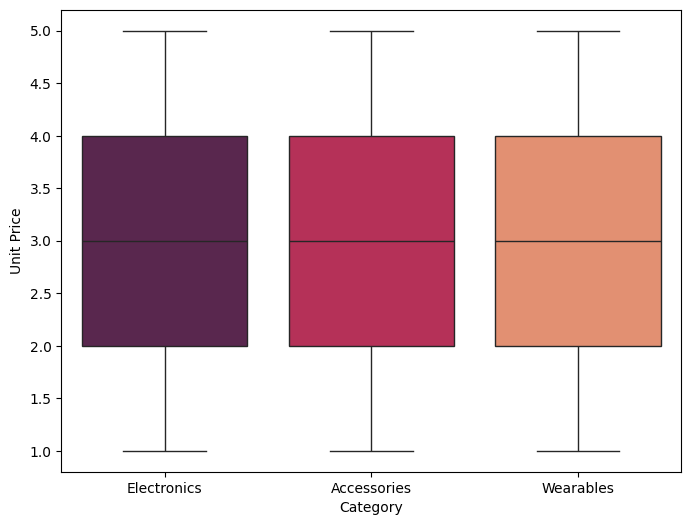

In [53]:
plt.figure(figsize=(8, 6))

sns.boxplot(x='category', y='quantity', data=df, palette=("rocket"))

plt.xlabel('Category')
plt.ylabel('Unit Price')

plt.show()

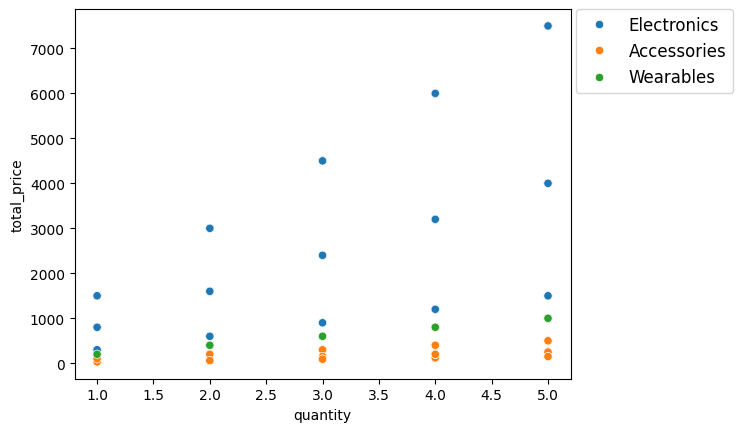

In [54]:
ax = sns.scatterplot(data=df, x='quantity', y='total_price' , hue='category', legend=True)


ax.legend( bbox_to_anchor=(1.01, 1), loc=2, borderaxespad=0., fontsize=12)
plt.show()

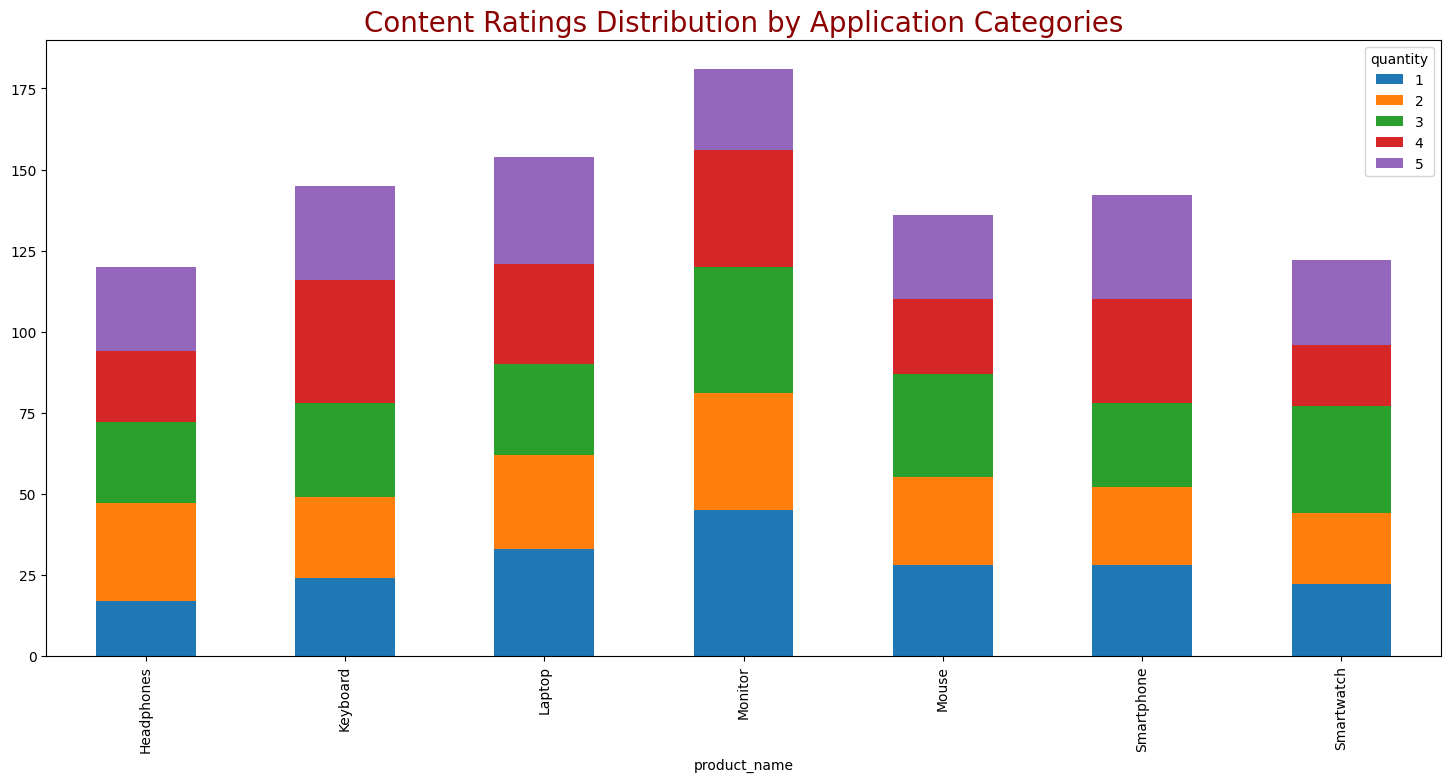

In [55]:
content_category_cross = pd.crosstab( df['product_name'], df['quantity'])

content_category_cross.plot(kind='bar', stacked=True, figsize=(18,8))

plt.title("Content Ratings Distribution by Application Categories", fontdict={'fontsize': 20, 'color': 'darkred'});

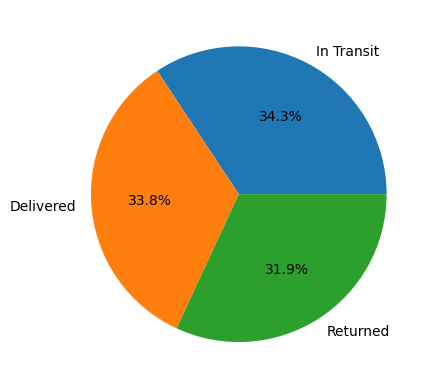

In [56]:
status = df2.shipping_status.value_counts()
plt.pie(x= status.values, labels = status.index, autopct='%1.1f%%');

In [57]:
df2['year'] = pd.DatetimeIndex(df2['order_date']).year

# Yıllara ve teslimat durumuna göre gruplama ve sayma
yearly_status = df2.groupby(['year', 'shipping_status']).size().unstack(fill_value=0)

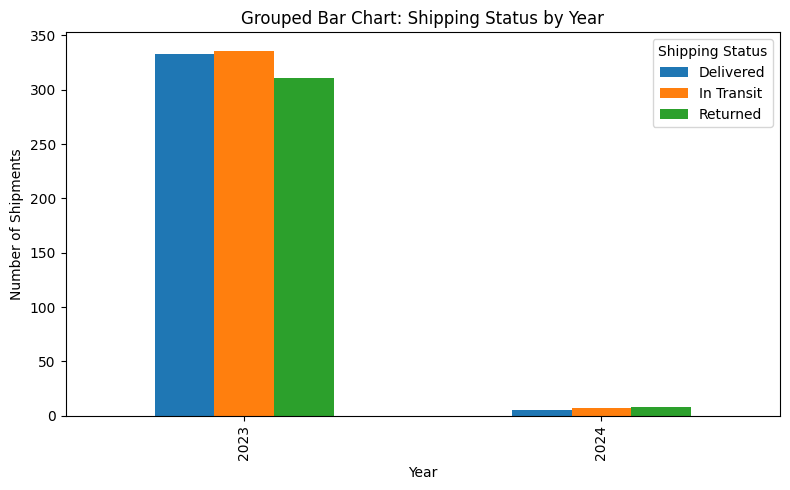

In [58]:
# 2. Grouped Bar Chart (Gruplu Çubuk Grafik)
yearly_status.plot(kind='bar', stacked=False, figsize=(8, 5))
plt.title('Grouped Bar Chart: Shipping Status by Year')
plt.xlabel('Year')
plt.ylabel('Number of Shipments')
plt.legend(title='Shipping Status')
plt.tight_layout()
plt.show()

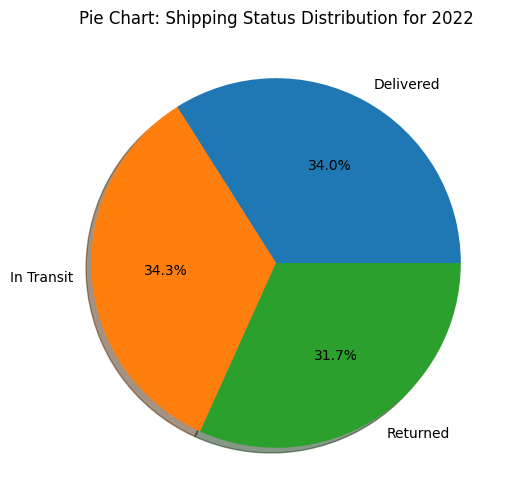

In [59]:
# 5. Pie Chart (Pasta Grafiği) - 2023 Yılına ait verileri pie chart ile gösterelim
yearly_status.loc[2023].plot(kind='pie', autopct='%1.1f%%', shadow=True, figsize=(6, 6))
plt.title('Pie Chart: Shipping Status Distribution for 2022')
plt.ylabel('')  # y-label'i gizleyelim çünkü pasta grafiğinde gerekli değil
plt.show()

<a id='save-data'></a>
##  <font color='firebrick'> <b>Save to Dataset</b><font color='black'>

In [60]:
df.to_csv('e-commerce_eda.csv', index=False)

<p style="background-color:firebrick;font-family:newtimeroman;font-size:200%;color:white;text-align:center;border-radius:20px 20px;"><b>THANK YOU!</b></p>